In [62]:
import warnings
import os 
from pathlib import Path

import pandas as pd
import scanpy as sc
import numpy as np 
from dotenv import dotenv_values
import matplotlib.pyplot as plt
import seaborn as sns
import random

warnings.simplefilter(action='ignore', category=FutureWarning)

In [8]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Supplemental"
os.makedirs(OUTDIR, exist_ok=True)

SC_IN_FP = DATADIR / "9_objects" / "singlecell" / 'hypomap3d_singlecell_control.h5ad'
OBS_EXT_FP = DATADIR / "9_objects" / "singlecell" / 'hypomap3d_singlecell_all_obs_extended.csv'

L2_INHERITANCE_FP = DATADIR / "10_analyses" / "clustering_comparison" / "inheritance_status_l2.csv"
L3_INHERITANCE_FP = DATADIR / "10_analyses" / "clustering_comparison" / "inheritance_status_l3.csv"

In [ ]:
adata = sc.read_h5ad(SC_IN_FP)

In [38]:
# Get additional data for ABC mapping
obs_ext = pd.read_csv(OBS_EXT_FP, low_memory=False)
adata.obs = adata.obs.merge(obs_ext, on="CellID", how="left")

/beegfs/home/mfeldmann/.local/share/uv/python/cpython-3.11.5-linux-x86_64-gnu/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


In [18]:
l2_n = pd.read_csv(L2_INHERITANCE_FP)
l2_n.source_label = l2_n.source_label.map(abc_to_descr_l2)

In [19]:
joined_n = pd.read_csv(L3_INHERITANCE_FP)
joined_n.source_label_subclass = joined_n.source_label_subclass.map(abc_to_descr_l2)

# Supplemental Info Fig 1

In [42]:
vmh = adata[adata.obs.L2_ID.isin(["Gl2-33", "Gl2-34", "Gl2-31", "Gl2-35"])].copy()

In [ ]:
# zooom in to remove outlier cells from the plot
vmh = vmh[(vmh.obsm["X_umap"][:, 1] > -10) & (
    vmh.obsm["X_umap"][:, 1] < 2) & (
    vmh.obsm["X_umap"][:, 0] > 19)
    ]

In [51]:
vmh.layers["raw"] = vmh.X.copy()
sc.pp.normalize_total(vmh, target_sum = 10_000) 
sc.pp.log1p(vmh,)

/tmp/ipykernel_70422/1701307893.py:1: ImplicitModificationWarning: Setting element `.layers['raw']` of view, initializing view as actual.
  vmh.layers["raw"] = vmh.X.copy()


In [55]:
genes_to_plot = ["Fezf1", "Nr5a1", "Acvr1c", "Bcl11b", "Nfix"]

In [73]:
vmax = np.max(vmh[:, genes_to_plot].X.toarray())

In [65]:
scattersize = 10

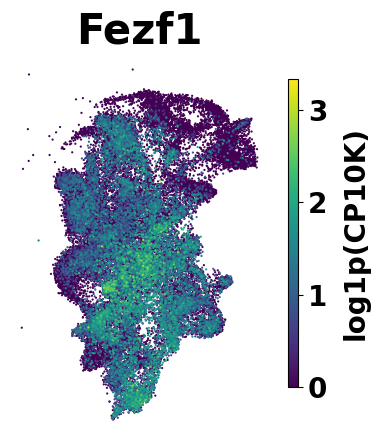

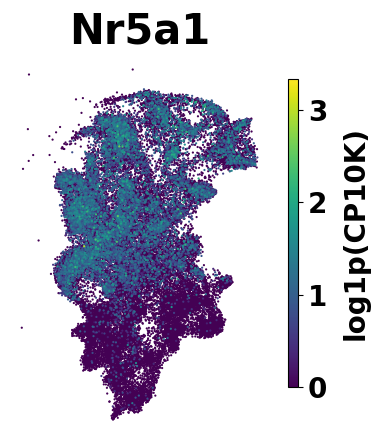

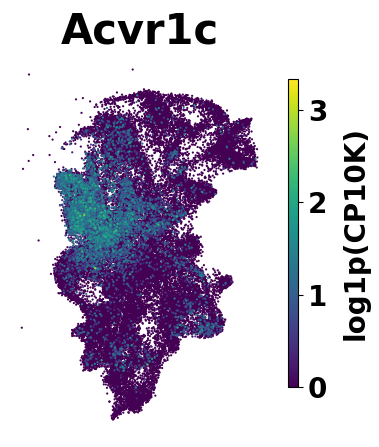

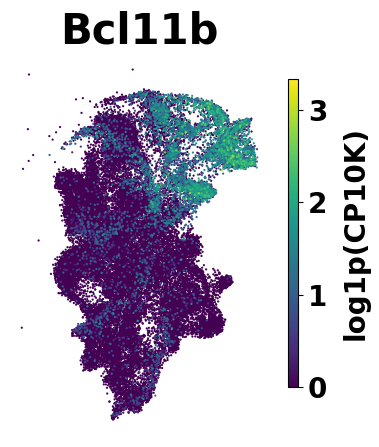

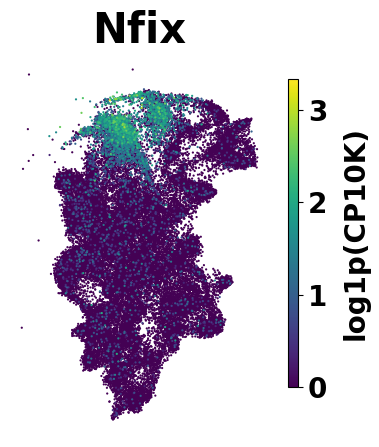

In [74]:

for gene in genes_to_plot:

    # Create high-resolution figure and axis
    fig, ax = plt.subplots(figsize=(5, 5)) 

    # Plot with Scanpy onto the given axis
    sc.pl.umap(
        vmh, 
        color=gene,
        ax=ax,
        show=False,
        size=scattersize,
        vmax=vmax
    )

    # --- Rasterize the scatter plot points ---
    for artist in ax.collections:
        artist.set_rasterized(True)

    # Remove default title, borders, ticks, and labels
    ax.set_title(gene, fontsize=30, fontweight="bold")
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_aspect('equal')

    # Modify the colorbar
    for cax in fig.axes:
        if cax != ax:
            # Shrink the colorbar by modifying its position
            pos = cax.get_position()
            cax.set_position([
                pos.x0 + 0.03,      # move right
                pos.y0 + 0.1,       # move up
                pos.width * 20,     # stretch horizontally
                pos.height * 0.8  # shrink vertically
            ])

            # Set label and tick styles
            cax.set_ylabel("log1p(CP10K)", fontsize=20, fontweight='bold', labelpad=10)
            cax.tick_params(labelsize=20)
            for label in cax.get_yticklabels():
                label.set_fontweight('bold')
            break
 
    # Save figure
    fig.savefig(
        OUTDIR / f"umap_{gene}_expr_C_only_vmh.pdf",
        dpi=300,
        format="pdf",
        bbox_inches="tight"
    )


In [67]:
colors_to_plot = ["subclass_id_label", "subclass_id_label_propagated", "L2_abc_like"]

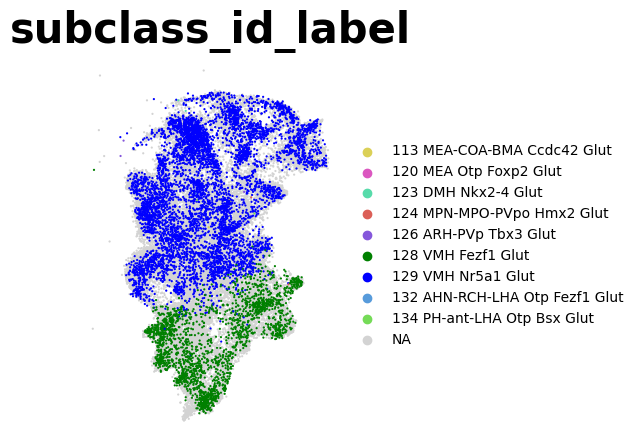

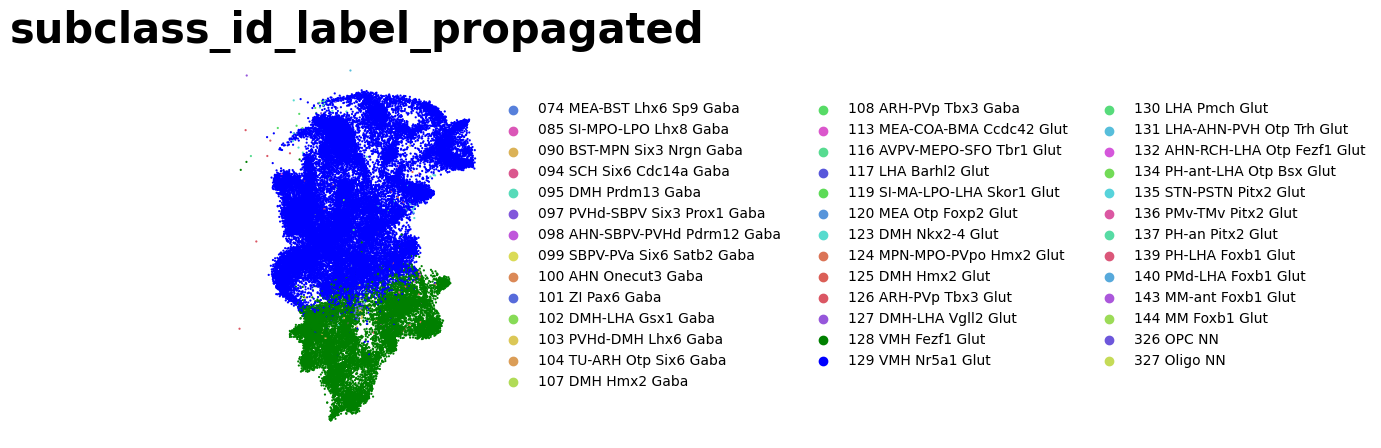

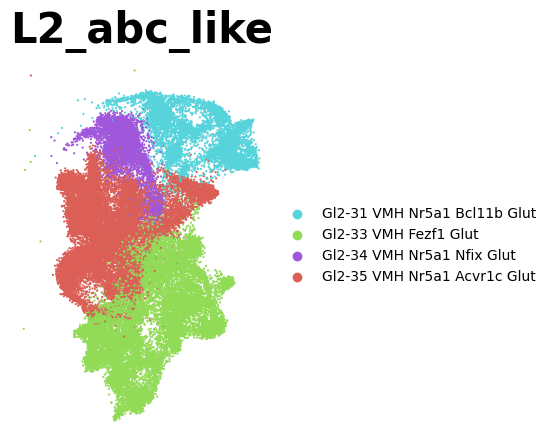

In [68]:
for color in colors_to_plot:
    # Ensure the column is categorical and has a defined category order
    vmh.obs[color] = vmh.obs[color].astype("category")
    categories = vmh.obs[color].cat.categories.tolist()

    # Define specific colors for known categories
    category_colors = {
        "129 VMH Nr5a1 Glut": "blue",
        "128 VMH Fezf1 Glut": "green"
    }

    # Determine which categories still need a color
    remaining_categories = [cat for cat in categories if cat not in category_colors]

    # Generate random distinct colors for the remaining ones
    random_palette = sns.color_palette("hls", len(remaining_categories))
    random.shuffle(random_palette)  # Optional: for extra randomness

    # Assign them to the remaining categories
    for cat, color_val in zip(remaining_categories, random_palette):
        category_colors[cat] = color_val

    # Create the final palette list in the correct order
    final_palette = [category_colors[cat] for cat in categories]

    # Plot
    fig, ax = plt.subplots(figsize=(5, 5))
    sc.pl.umap(
        vmh,
        color=color,
        ax=ax,
        show=False,
        size=scattersize,
        palette=final_palette
    )

    for artist in ax.collections:
        artist.set_rasterized(True)

    ax.set_title(color, fontsize=30, fontweight="bold")
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_aspect('equal')

    fig.savefig(
        OUTDIR / f"umap_{color}_only_vmh.pdf",
        dpi=300,
        format="pdf",
        bbox_inches="tight"
    )


/tmp/ipykernel_70422/3983992318.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([f"{tick:.2f}" for tick in ax.get_yticks()], fontsize=16, fontweight="bold")


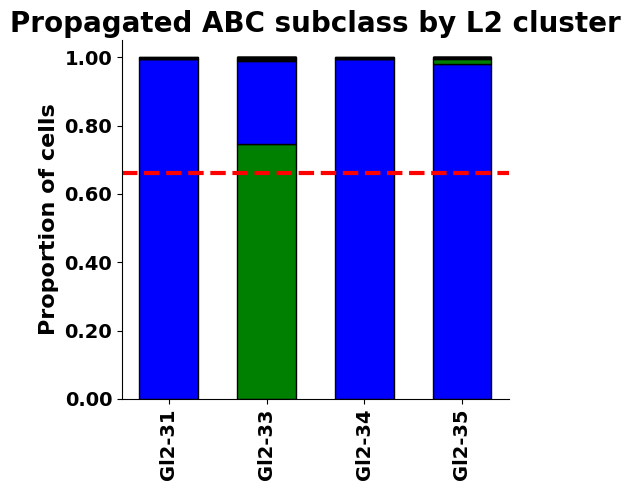

In [72]:
# Ensure categorical types
vmh.obs["L2_abc_like"] = vmh.obs["L2_abc_like"].astype("category")
vmh.obs["subclass_id_label_propagated"] = vmh.obs["subclass_id_label_propagated"].astype("category")

# Get ordered categories
l2_categories = vmh.obs["L2_abc_like"].cat.categories
abc_categories = vmh.obs["subclass_id_label_propagated"].cat.categories
abc_colors = vmh.uns["subclass_id_label_propagated_colors"]

# Build color mapping
abc_color_dict = dict(zip(abc_categories, abc_colors))

# Build count and proportion dataframe
count_df = pd.crosstab(vmh.obs["L2_abc_like"], vmh.obs["subclass_id_label_propagated"])
proportion_df = count_df.div(count_df.sum(axis=1), axis=0)

# Start plotting
fig, ax = plt.subplots(figsize=(5, 5
))
x = np.arange(len(proportion_df))
bar_width = 0.6

# Draw each bar individually
for i, l2 in enumerate(proportion_df.index):
    subclass_proportions = proportion_df.loc[l2]
    
    # Sort subclasses for this L2 group by their proportion (descending)
    sorted_subclasses = subclass_proportions.sort_values(ascending=False)
    
    bottom = 0
    for subclass, value in sorted_subclasses.items():
        if value == 0:
            continue  # skip subclasses not present in this L2 group
        ax.bar(
            x[i],
            value,
            bottom=bottom,
            color=abc_color_dict[subclass],
            edgecolor='black',
            width=bar_width,
            label=subclass if i == 0 else None  # only label once for legend
        )
        bottom += value

# Format x-tick labels: take first token before space
short_xticklabels = [label.split(" ")[0] for label in proportion_df.index]
ax.set_xticks(x)
ax.set_xticklabels(short_xticklabels, rotation=90, fontsize=16, fontweight="bold")

# Format y-axis
ax.set_ylabel("Proportion of cells", fontsize=16, fontweight="bold")
ax.set_yticklabels([f"{tick:.2f}" for tick in ax.get_yticks()], fontsize=16, fontweight="bold")

# Title
ax.set_title("Propagated ABC subclass by L2 cluster", fontsize=20, fontweight="bold")

# Horizontal line at 0.66
ax.axhline(0.66, color="red", linestyle="--", linewidth=3)

# Despine
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Ticks styling
ax.tick_params(axis='both', labelsize=14)

# # Legend
# handles, labels = ax.get_legend_handles_labels()
# unique = dict(zip(labels, handles))  # remove duplicates
# legend = ax.legend(
#     unique.values(), 
#     unique.keys(), 
#     title="ABC Subclass", 
#     bbox_to_anchor=(1.05, 1), 
#     loc='upper left',
#     fontsize=14, 
#     title_fontsize=16
# )
# plt.setp(legend.get_title(), fontweight='bold')
# plt.setp(legend.get_texts(), fontweight='bold')

plt.tight_layout()


fig.savefig(
    OUTDIR / f"vmh_bars.pdf",
    dpi=300,
    format="pdf",
    bbox_inches="tight"
)


plt.show()


# Supplemental Info Fig 2

In [36]:
l2_n[l2_n.source_label.str.contains("PVHd-DMH Lhx6")]

,source_label,most_probable_match,most_probable_match_counts_relative,is_inherited,hm3d_stem,abc_stem,num_valid_abc_match_occurrences,is_deduplicated,inheritance_status
1,Gb2-40 PVHd-DMH Lhx6,103 PVHd-DMH Lhx6 Gaba,0.964919,True,PVHd-DMH Lhx6 GABA,PVHd-DMH Lhx6 GABA,1.0,False,inherited


In [33]:
joined_n.loc[joined_n.source_label_subclass.str.contains("PVHd-DMH Lhx6"), 
    ["source_label_supertype", "most_probable_match_supertype", "most_probable_match_counts_relative_supertype"]].sort_values(by="most_probable_match_supertype")

,source_label_supertype,most_probable_match_supertype,most_probable_match_counts_relative_supertype
8,Gb3-132 PVHd-DMH Lhx6 GABA_2,0475 PVHd-DMH Lhx6 Gaba_2,0.961345
6,Gb3-130 PVHd-DMH Lhx6 GABA_3a,0476 PVHd-DMH Lhx6 Gaba_3,0.708054
7,Gb3-131 PVHd-DMH Lhx6 GABA_3b,0476 PVHd-DMH Lhx6 Gaba_3,0.801211
5,Gb3-129 PVHd-DMH Lhx6 GABA_5,0477 PVHd-DMH Lhx6 Gaba_4,0.482285


In [35]:
adata.obs.loc[adata.obs.L3_ID == "Gb3-130", ["L3_abc_like", "L4_abc_like", "L5_abc_like"]].drop_duplicates().sort_values(by="L4_abc_like")

,L3_abc_like,L4_abc_like,L5_abc_like
SC1-01_SAMN18754354_TATCAGGGTCTAGATC,Gb3-130 PVHd-DMH Lhx6 GABA_3a,Gb4-342 PVHd-DMH Lhx6 GABA_3a-1,Gb5-455 PVHd-DMH Lhx6 GABA_3a-1-1
SC1-01_SAMN18754357_AATCGTGGTACGATGG,Gb3-130 PVHd-DMH Lhx6 GABA_3a,Gb4-342 PVHd-DMH Lhx6 GABA_3a-1,Gb5-456 PVHd-DMH Lhx6 GABA_3a-1-2
SC1-01_SAMN18754358_AGTTCCCTCACGTAGT,Gb3-130 PVHd-DMH Lhx6 GABA_3a,Gb4-342 PVHd-DMH Lhx6 GABA_3a-1,Gb5-457 PVHd-DMH Lhx6 GABA_3a-1-3
SC1-01_SAMN18754354_AGTGACTGTAGTCGGA,Gb3-130 PVHd-DMH Lhx6 GABA_3a,Gb4-343 PVHd-DMH Lhx6 GABA_3a-2,Gb5-458 PVHd-DMH Lhx6 GABA_3a-2-1
